# 2. zárthelyi dolgozat, A) változat (2026. 05. 22.)

**A második zárthelyi dolgozat során egy mély konvolúciós neuronhálót (CNN) tanítunk be képek bináris klasszifikációjára a PyTorch könyvtár segítségével. A Pascal VOC képi adatbázis egy kisméretű részhalmazából indulunk ki, mely képeket tartalmaz, rajtuk, egyebek mellett, húsz fajta kitüntett típusú objektummal (repülőgép, kerékpár, madár, stb.). Az adatbázisban a képekhez pixel-szintű (szegmentációs) címkék érhetők el - egy képen többfajta objektum is lehet, egyenként több példánnyal. Elsőként azonosítjuk azokat a képeket, melyeken a kitüntetett objektumok (típusuktól függetlenül) együttesen csak kis számú pixelt foglalnak el, illetve azokat, melyeken az objektumok a pixelek nagy részét elfoglalják. A neuronhálónkat a két kategóriába eső képek megkülönböztetésére tanítjuk be. A neuronhálónk alapját egy, az ImageNet adatbázison előtanított mélyháló (MobileNet 2) adja, melynek architektúráját kisebb átalakításokkal alkalmassá tesszük a feladatunk megoldására, majd finomhangoljuk azt. Mivel nem áll rendelkezésünkre sok címkézett kép a számunkra fontos kategóriákban, ezért adat-augmentációt is fogunk használni a betanításhoz.**

A zárthelyi több részfeladatból áll (A - G), melyek A-tól F-ig egymásra épülnek, a G feladat függetlenül a többitől megoldható. A feladat automatikus tesztelőszkripttel rendelkezik és vizsgálja az egyes részfeladatokra adott megoldások helyességét. Éppen ezért, **ne változtasd meg a notebook struktúráját**, ne szedd több részre, illetve ne módosítsd a megírt részeket, csak a megoldásaidat írd be a megfelelő helyre, különben nem fogjuk tudni értékelni! A megoldások az `# Implement your solution BELOW` és `# Implement your solution ABOVE` sorok közé írandók. Ha a megoldott részfeladatok futtatásakor a "Tester: .... OK" felirat megjelenik, a tesztelőszkript nem talált hibát a megoldásban, azonban, a tesztelő nem teljeskörű, nem vesz észre mindenfajta hibát.

**A feladatban elérhető klasszifikációs pontosság:** Körülbelül 88-96 % közti (bináris) accuracy érhető el a teszthalmazon a feladat helyes megoldásával. Ha ennél jelentősen rosszabb, vagy jelentősen jobb az eredmény, amit a neuronháló legfeljebb elér a teszthalmazon, akkor hibára lehet gyanakodni és meg kell próbálni azt megtalálni: a részfeladatok eredményeit össze lehet például vetni a feladatok szövegével és az eredeti, szöveges fájlban letöltött adatbázissal.

**A megoldott feladatsor beadása:** A kész megoldást tartalmazó notebookot (.ipynb) fájlként kell feltölteni a Canvas-ban, a "2. zárthelyi dolgozat" beadási felületén.

**További szabályok:**
- Kérjük a notebook szerkezetét nem módosítani és nem szétszedni külön feladatok szerint!
- A zárthelyi megoldásához, kizárólag, a Canvas feladatból letöltött .zip fájl tartalma és a Canvasban a saját profilból, már a ZH kezdetekor is elérhető tartalom használható fel. Kommunikáció csak az oktatókkal engedélyezett a ZH ideje alatt.

**Rendelkezésre álló idő:** 160 perc

**Értékelés:** Legfeljebb 45 pont gyűjthető: lásd a részfeladatokra adható pontokat az egyes feladatoknál. Minimum 22 pontot el kell érni ezen a zárthelyin a tárgy teljesítéséhez - ha ez nem sikerül, javító ZH megírása lesz szükséges.

**Kikötés:** Nagy számú iterációt (50+) végrehajtó ciklus és hasonló, nem hatékony konstrukció a kódban pontlevonást eredményezhet. Sok ezer pixelt felsoroló iteráció még inkább kerülendő! Kivételek, ahol büntetés nélkül használható hosszabb ciklus:
- Az A) feladatban a képek felsorolására (de nem a pixelek feletti iterálásra).
- A háló betanításánál/kiértékelésénél, a tanítási/validációs/teszt loopban, akár epoch-ok, akár batch-ek iterálására.
- A háló paramétereinek felsorolására.
- A G) feladatban az "Alapfeladat" esetében.


---

Tesztelő szkript letöltése, importok.

In [ ]:
import os
import tarfile
import PIL
from PIL import Image
import io
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms
import torchvision.transforms.v2
import skimage
import time

import matplotlib.pyplot as plt

from PascalVOC_CNN_Tester import Tester
tester = Tester()

Az adatbázis beolvasása.

In [ ]:
jpg_ims = []
label_ims = []

# unpacking tar content directly into memory and decoding jpg/png images from there to avoid working with many small files on disk
with tarfile.open("PascalVOC_annbsc_tiny.tar", "r") as tar:
    tar_members = tar.getmembers()
    tar_jpg_members = [member for member in tar_members if member.name[-4:] == '.jpg']  # list only jpg images, not label images
    for jpg_member in tar_jpg_members:
        filename_noext = os.path.split(jpg_member.name)[-1][:-4]

        # get next jpg image
        file_in_tar = tar.extractfile(jpg_member)
        byte_arr = np.asarray(bytearray(file_in_tar.read()), dtype=np.uint8)
        pil_image = Image.open(io.BytesIO(byte_arr))
        npy_image = np.asarray(pil_image)
        assert npy_image.dtype == np.uint8
        jpg_ims.append(npy_image)

        # get label image corresponding to the jpg image
        label_member_name = 'PascalVOC_annbsc_data/SegmentationClass/' + filename_noext + '.png'
        file_in_tar = tar.extractfile(label_member_name)
        byte_arr = np.asarray(bytearray(file_in_tar.read()), dtype=np.uint8)
        pil_image = Image.open(io.BytesIO(byte_arr))  # using PIL instead of cv2 as it supports loading palette coded png images as single channel integer arrays
        npy_image = np.asarray(pil_image)
        assert npy_image.dtype == np.uint8
        label_ims.append(npy_image)

jpg_ims = np.stack(jpg_ims, axis=0)
label_ims = np.stack(label_ims, axis=0)

# removing 'border region' (255) from label images and replacing it with background (0)
label_ims[label_ims == 255] = 0

print("Image & label data was loaded into 'jpg_ims', 'label_ims' NumPy arrays. Shapes:", jpg_ims.shape, label_ims.shape)


Image & label data was loaded into 'jpg_ims', 'label_ims' NumPy arrays. Shapes: (2913, 240, 320, 3) (2913, 240, 320)


**Adatbázis:** A feladat során a Pascal VOC adatbázis egy csökkentett felbontású részhalmazával kell dolgozni. Az adatbázisban húsz kategóriába (plusz "háttér") sorolt objektumokról készült képek vannak. A színes képekhez azonos felbontású szegmentációs címke tartozik, mely minden pixelre meghatározza annak szemantikus kategóriáját.

Az `(n_images, size_y=240, size_x=320, n_channels=3)` alakú, `np.uint8` adattípusú `jpg_ims` tömb tartalamazza a különböző állatokról, emberekről, járművekről és egyéb tárgyakról készült képeket. A `label_ims` tömb az említett képekhez rendelt szegmentációs címkéket tárolja. Ennek alakja `(n_images, size_y=240, size_x=320)`, adattípusa ugyancsak `np.uint8`. Az egy-egy képhez tartozó szegmentációs címke, a színes képekkel megegyező felbontású egycsatornás kép, mely minden egyes pixelre megadja az ahhoz rendelt szemantikus kategóriát egy integer formájában. Az adatbázis húsz fajta objektumot (élőlényt/tárgyat) különböztet meg, ezek 1 és 20 közti egész számokkal vannak reprezentálva. Azok a pixelek, melyek egyik kiemelt objektumtípushoz sem tartoznak, a "háttér" (background) kategóriába soroltak és 0 értéket kapnak a szegmentációs címkén.

Elsőként belenézünk a letöltött adatbázis tartalmába és kirajzolunk néhány képet a hozzájuk tartozó szegmentációs címkékkel együtt.

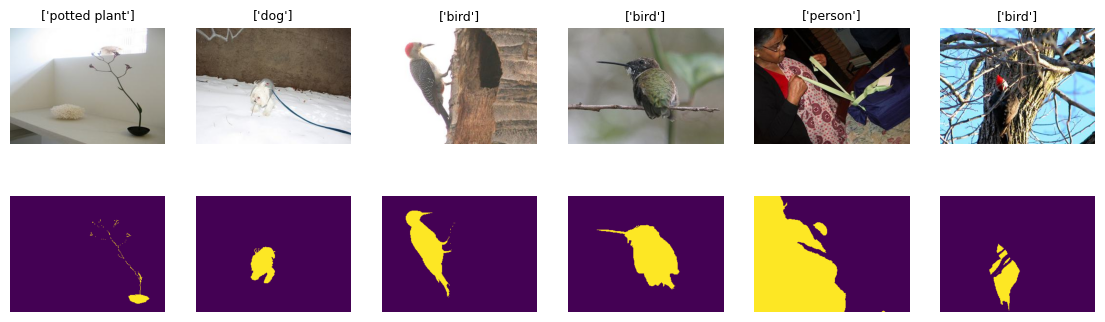

In [4]:
ORIG_CAT_NAMES = ['background', 'aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cow', 'dining table', 'dog', 'horse', 'motorbike', 'person', 'potted plant', 'sheep', 'sofa', 'train', 'tv/monitor']

# implement your solution BELOW

sample_idxs = np.random.choice(jpg_ims.shape[0], size=6)
sample_jpg_ims = jpg_ims[sample_idxs,:,:,:]
sample_label_ims = label_ims[sample_idxs,:,:]

fig, axs = plt.subplots(2, 6)
fig.set_figheight(4)
fig.set_figwidth(14)
for plot_idx in range(6):
    axs[0, plot_idx].imshow(sample_jpg_ims[plot_idx])
    axs[1, plot_idx].imshow(sample_label_ims[plot_idx])
    axs[0, plot_idx].axis('off')
    axs[1, plot_idx].axis('off')
    u_labs = np.unique(sample_label_ims[plot_idx,:,:])
    text = str([ORIG_CAT_NAMES[lab] for lab in u_labs if lab > 0])
    axs[0, plot_idx].set_title(text, fontsize=9)


### **A**: A bináris klasszifikációhoz releváns képek kiválogatása - 6 pont

A következőkben kiválogatjuk azokat a képeket, melyeken a releváns objektumok együttesen kevés számú pixelt foglalnak el, illetve azokat, melyeken együttesen nagy számú pixelt foglalnak el. A két kategóriába eső képekhez egyszerű bináris klasszifikációs címkéket hozunk létre, melyeket egy tömbben helyezünk el. Az így kapott adathalmazt fogjuk felhasználni a neuronhálónk betanítására és kiértékelésére.

Készítsd el az `imgs` és `labels` tömböket az alábbiak szerint!
- Kerüljön az `imgs` tömbbe az összes olyan kép a `jpg_ims` tömbből, melyen a releváns objektumok **összesen legfeljebb a pixelek 8 százalékát foglalják el**, illetve azok, melyen a releváns objektumok **együttesen legalább a pixelek 40 százalékát foglalják el**! Előbbiek alkotják majd a **"szellős képek" kategóriáját**, utóbbiak pedig a **"zsúfolt képek" kategóriáját**. A különböző objektumok jelenlétét a képeken, a `label_ims` tömbben található megfelelő képeken jelen levő 1, 2, ..., 20 értékű pixelek jelzik.
- A `labels` tömb a fenti, kiválasztott képekhez rendel bináris klasszifikációs címkéket aszerint, hogy azok a "szellős", vagy "zsúfolt" képek kategóriájába tartoznak. Előbbieket 0, utóbbiakat 1-es értékekkel jelöljük a tömbben.

Az `imgs` tömb alakja tehát hasonló a `jpg_ims` tömbhöz, viszont kevesebb képet tartalmaz, hiszen az eredeti képeknek csak egy részét választottuk ki: `(n_kiválasztott_kép, 240, 320, 3)`. A `labels` tömb alakja ennek megfelelően `(n_kiválasztott_kép,)`: minden egyes képhez egy bináris klasszifikációs címkét tárol el.


In [44]:
# Note that a pairwise comparison of all pixels in all images against an array with 20 elements at the same time can use up all the available memory.

# implement your solution BELOW
n_images = label_ims.shape[0]
number_of_pictures = 0
labels = np.full((n_images,), dtype=np.uint8, fill_value=99)
imgs = np.zeros_like(jpg_ims)
for im_idx in range(n_images):
    c_categories = np.bincount(label_ims[im_idx, :, :].reshape(-1), minlength=21)
    #object_present_mask = c_categories != 0
    sum_of_relevant_pixels = np.sum(c_categories[1:])
    if sum_of_relevant_pixels <= 240*320*0.08:
        imgs[im_idx] = jpg_ims[im_idx]
        labels[im_idx] = 0 #0 a szellős, 1 a zsúfolt
        number_of_pictures += 1
    elif sum_of_relevant_pixels >= 240*320*0.4:
        imgs[im_idx] = jpg_ims[im_idx]
        labels[im_idx] = 1
        number_of_pictures += 1

correct_images_mask = labels != 99
labels = labels[correct_images_mask]
labels = labels[:number_of_pictures]
imgs = imgs[correct_images_mask]
imgs = imgs[:number_of_pictures]




# implement your solution ABOVE

tester.test('A', imgs, labels)

Tester: Task A - OK



### **B**: Felbontás tanító-, validációs- és teszthalmazra - 3 pont

**Keverd meg véletlenszerűen a mintaelemeket** az adatbázisban! Ezt általánosságban azért célszerű megtenni, mert az előző feladatban esetlegesen egymás mellett helyeztük el az azonos kategóriájú képeket. Megkeverés nélkül, a szétválasztott halmazokban jelentősen különbözhetne a címkék eloszlása. Figyelj rá, hogy a keverés azonos sorrendű legyen az `imgs` és a `labels` tömb elemein!

Ezt követően **válaszd szét** (konzisztens módon) **a megkevert, képeket tartalmazó tömböt és az ahhoz tartozó címketömböt tanító-, validációs- és teszthalmazra**! Kerüljön 200-200 mintaelem a validációs- és teszthalmazba, majd a maradék a tanítóhalmazba (a sorrend mindegy)!  Állítsuk elő így, az

  - `imgs_train`, `imgs_val`, `imgs_test` nevű, képeket tartalmazó tömböket, illetve, a hozzájuk tartozó
  - `labels_train`, `labels_val`, `labels_test` nevű címketömböket!


In [45]:
# implement your solution BELOW

n_total_samples = labels.shape[0]
perm = np.random.permutation(n_total_samples)
imgs = imgs[perm]
labels = labels[perm]

imgs_test = imgs[:200]
imgs_val = imgs[200:400]
imgs_train = imgs[400:]

labels_test = labels[:200]
labels_val = labels[200:400]
labels_train = labels[400:]


# implement your solution ABOVE

tester.test('B', imgs_train,   imgs_val,   imgs_test, \
                 labels_train, labels_val, labels_test)

Tester: Task B - OK


### **C**: Az adat-iterátorok létrehozása a bináris klasszifikációs feladathoz, adat-augmentáció - 8 pont

A házi feladatokhoz és az előző zárthelyihez hasonlóan, ezúttal is iterátorokkal oldjuk meg a neuronhálónk betanítását. Ebben a részfeladatban **elő kell állítanod három iterálható objecktumot (Iterable)** `dataloader_train`, `dataloader_val` és `dataloader_test` néven, melyek az előző részfeladatban elkészített megfelelő részhalmazhoz tartozó képtömb-címketömb párosokból képeket és a hozzájuk tartozó bináris klasszifikációs címkéket felsoroló iterátorokat képesek visszaadni!

Például, a `dataloader_train` által visszaadott iterátor az `imgs_train` és a `labels_train` tömbökből sorolja fel a képeket és a hozzájuk tartozó címkéket. Hasonlóan, a validációs és a teszt iterátorok a további két képtömb-címketömb párossal dolgoznak.

**A képek felbontását a kötegekbe sorolás előtt csökkentjük** 192 x 192 pixelre, azért, hogy a neuronhálónk számításigénye kisebb legyen. Ezt megteheted, többek közt, a NumPy tömbökön operáló `skimage.transform.resize()` függvénnyel, vagy később, a `torchvision.transforms.v2` pipeline-jában is (`torchvision.transforms.v2.Resize` osztály). Utóbbi használata esetén, a `Resize` példányt a tenzorrá alakítást követően kell elvgezned a pipeline-ban. Fontos, hogy ne képkivágást használj, hanem átméretezést, hiszen a képkivágás elképzelhető, hogy levágná a lényeget a képről!

**Az iterátorok minden lépésben két tenzort adnak vissza**, melyek egy-egy kötegnyi input képet és azokhoz tartozó bináris klasszifikációs címkéket tartalmaznak.

A képek esetén szükséges lesz a tengelyek sorrendjének átrendezése, mivel a csatornákat felsoroló tengely eddig hátul volt (_channel-last_ formátum: NHWC), de a PyTorch erre a tengelyre közvetlenül a kötegméret tengely után számít (_channel-first_ formátum: NCHW). Ebből kifolyólag, a visszaadott tenzorok alakja `(batch_size, 3, 192, 192)` és `(batch_size, 1)` lesz. Előbbi a színes képeket tartalmazza, utóbbi a képekhez tartozó bináris klasszifikációs címkéket. `batch_size` a mintaelemek számát adja meg, melyeket egyszerre, egy kötegben fog megkapni a neuronhálónk - ennek értéke lehet például 32.

Hangsúlyozandó, hogy az iterátorok a fent említett NumPy tömbökből (`np.ndarray`) nyert mintaelem-kötegeket már `torch.tensor` típusú objektumokként adják vissza (pontosabban, kételemű tuple-öket adnak vissza, melyekben `torch.tensor` objektumok lesznek). A PyTorch-al definiált neuronhálók betanításához már mindenképp PyTorch tenzorok szükségesek: az input tenzor és a bináris címkéket tartalmazó tenzor **adattípusa** is 4 bájtos lebegőpontos típus (`torch.float32`) kell, hogy legyen.

A neuronhálónk egy előtanított mély konvolúciós hálón alapul majd, ezért a képeinket olyan formátumra kell hoznunk, amilyet a háló a betanításakor látott. Az eredetileg [0, 255] intervallumbeli értékeket tartalmazó képeinket először a [0, 1] intervallumra kell leskáláznunk, majd színcsatornánként megadott átlag (`MOBILENET_MEANS`) és szórás (`MOBILENET_STDS`) értékekkel kell **sztenderdizálnunk**. Az iterátor által visszaadott képek színcsatornánként függetlenül vett átlaga tehát 0 körül, szórása pedig 1 körül lesz a helyes sztenderdizáció után.

Az iterátorok implementációja többféleképpen megoldható. Például, egyedi generátorral/iterátorral, vagy a `torch.utils.data` modul `Dataset` és `DataLoader` osztályai felhasználásával és esetleges származtatásával.

**Adat-augmentáció:** Sajnos a néhány száz képből álló adatbázisunkra hamar túltanulna a hálónk és nincs lehetőségünk új tanítóadatot beszerezni, így az adat-augmentálás technikájához kell fordulnunk. Azért, hogy valóban növeljük az adatbázisunkban a képek változatosságát, az adat-augmentációt nem előzetesen alkalmazzuk az egész adatbázison egyben, hanem dinamikusan hajtjuk végre, véletlenszerűen választott transzformációkkal minden újabb mintaelemen, vagy kötegen.

**Alkalmazz véletlenszerű adat-augmentációt a tanító** iterátorban, hogy csökkentsd a túltanulás valószínűségét! **Ne alkalmazz adat-augmentációt a validációs és teszt iterátorokban!** Figyelj rá, hogy **csak olyan adat-augmentációs módszereket alkalmazz, melyek nem változtatják meg jelentős mértékben a képen található releváns objektumok által lefedett pixelek arányát!** Azaz, ne alkalmazz skálázást, eltolást és nagymértékű forgatást! Alkalmazhatsz kis szöggel való forgatást, zajt és a kép színeinek torzítását! Az adat-augmentációhoz javasolt (de nem kötelező) a `torchvision.transforms.v2` modul eszközeit használni. Ennek segítségével a sztenderdizáció is megoldható.


In [46]:
MOBILENET_MEANS = [0.485, 0.456, 0.406]
MOBILENET_STDS = [0.229, 0.224, 0.225]   # MobileNet v2 stats used for image normalization

# implement your solution BELOW


class ImageClassificationDataset(Dataset):
    def __init__(self, imgs, labels, transform):
        self.imgs = imgs
        self.labels = labels
        self.transform = transform


    def __len__(self):
        return self.labels.shape[0]

    def __getitem__(self, idx):
        final_image=self.transform(self.imgs[idx])
        label = torch.tensor([self.labels[idx]], dtype=torch.float32)
        return final_image, label


train_transform = transforms.v2.Compose([
    
    transforms.v2.ToImage(),
    transforms.v2.ToDtype(torch.float32, scale=True),
    transforms.v2.Resize(size = (192,192)),
    transforms.v2.RandomErasing(p=0.05),
    transforms.v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
    transforms.v2.RandomAffine(degrees=5.),
    torchvision.transforms.Normalize(MOBILENET_MEANS, MOBILENET_STDS)
])

eval_transform = transforms.v2.Compose([
    transforms.v2.ToImage(),
    transforms.v2.ToDtype(torch.float32, scale=True),
    transforms.v2.Resize(size = (192,192)),
    torchvision.transforms.Normalize(MOBILENET_MEANS, MOBILENET_STDS)
])


train_dataset = ImageClassificationDataset(imgs_train, labels_train, transform=train_transform)
val_dataset = ImageClassificationDataset(imgs_val, labels_val,transform=eval_transform)
test_dataset = ImageClassificationDataset(imgs_test, labels_test, transform=eval_transform)

dataloader_train = DataLoader(train_dataset, batch_size=32, shuffle=True)
dataloader_val = DataLoader(val_dataset, batch_size=32, shuffle=True)
dataloader_test = DataLoader(test_dataset, batch_size=32, shuffle=False)

# implement your solution ABOVE

tester.test('C', dataloader_train, dataloader_val, dataloader_test)          # Use this for "Alapfeladat"
#tester.test('C_extra', dataloader_train, dataloader_val, dataloader_test)    # Use this for "Extra feladat"

Tester: Task C, 'Alapfeladat' - OK


### **D**: A konvolúciós háló definiálása bináris klasszifikációhoz - 5 pont

A konvolúciós hálónk alapját egy, az ImageNet adatbázison előtanított MobileNet v2 neuronháló adja. Ezt alapul véve (és a tanult súlyainak nagyrészét felhasználva) készítjük el a célfeladat megoldására alkalmas neuronhálónkat, amit finomhangolunk az adatbázisunkon.

**Definiáld a bináris klasszifikációs feladathoz alkalmazandó neuronhálót megvalósító osztályt**, mely az általános `torch.nn.Module` osztály leszármazottja!

Töltsd be a MobileNet v2 neuronhálót előtanított súlyokkal, majd ennek egyik utolsó konvolúciós rétegéhez (ajánlott: `features[17].conv[3]`) fűzz hozzá pontosan

- **egy konvolúciós réteget 20 darab 3x3 méretű filterrel,**
- **majd, ezt követően egyetlen teljesen összekötött réteget,**

ami már a bináris klasszifikációhoz szükséges kimenetet adja! **Aktivációs függvény(eke)t ennek megfelelően kell alkalmaznod!** Mivel szükséges, hogy nagyon rövid idő alatt betanítható legyen ez a háló, **fagyaszd be az előtanított MobileNet hálóhoz tartozó paramétereket** (azaz ne legyenek ezek a paraméterek taníthatóak). Az általad hozzáadott rétegek paramétereit természetesen nem szabad befagyasztani.

**Példányosítsd az új osztályt** és add értékül a `finetuned_model` nevű változónak a példányt!


In [47]:
'''
# In order to load the MobileNet v2 pre-trained weights without internet access
# REPLACE THIS LINE:

self.mobile_net = torch.hub.load('pytorch/vision:v0.10.0', 'mobilenet_v2', weights='MobileNet_V2_Weights.IMAGENET1K_V1')

# WITH THESE FOUR LINES:

self.mobile_net = torch.hub.load(repo_or_dir='./mobilenet_weights/', model='mobilenet_v2', source='local')
checkpoint = os.path.join('./mobilenet_weights/', 'mobilenet_v2-b0353104.pth')
mobile_net_state_dict = torch.load(checkpoint, weights_only=True)
self.mobile_net.load_state_dict(mobile_net_state_dict)
'''

# implement your solution BELOW

class MobileNet2_FineTunedForBinaryClassClassification(nn.Module):

    def __init__(self):
        super().__init__()
        self.mobile_net = torch.hub.load(repo_or_dir='./mobilenet_weights/', model='mobilenet_v2', source='local')
        checkpoint = os.path.join('./mobilenet_weights/', 'mobilenet_v2-b0353104.pth')
        mobile_net_state_dict = torch.load(checkpoint, weights_only=True)
        self.mobile_net.load_state_dict(mobile_net_state_dict)
        self.mobile_net_output = None
        self.mobile_net.features[17].conv[3].register_forward_hook(self._hook)
        for param in self.mobile_net.parameters():            # freeze all weights of the original MobileNet network
          param.requires_grad = False  


        self.extra_conv = nn.Conv2d(320, 40, kernel_size = (3,3), padding='same')  # out: (bs, 320, 4, 4) if input size is (192, 192) 96,48,24,12
        self.extra_fc = nn.Sequential(
            nn.ReLU(),
            nn.Linear(40*6*6, 20),
            nn.ReLU(),
            nn.Linear(20, 1),
            nn.Sigmoid()
        )

    def _hook(self, module, input, output):
        self.mobile_net_output = output   # (batch_size, 320, 4, 4)

    def forward(self, x):
        _ = self.mobile_net(x)
        out = self.extra_conv(self.mobile_net_output)
        out = out.reshape(out.size(0), -1)
        out = self.extra_fc(out)
        return out


finetuned_model = MobileNet2_FineTunedForBinaryClassClassification()



# implement your solution ABOVE

tester.test('D', finetuned_model)

Tester: Task D might be OK. Note, that the exact architecture is not checked with this test.


### **E**: Néhány augmentált kép kirajzolása - 1 pont

Azért, hogy lássuk, a hálónk megfelelő inputot és címkéket fog kapni, mintavételezünk pár képet és címkét a C) feladatban elkészített iterátorokból és kirajzoljuk ezeket.
- Mintavételezz néhány képet és a hozzájuk tartozó címkéket a `dataloader_train` és `dataloader_val` iterátorokból, majd rajzold ki ezeket a képeket és írd föléjük a hozzájuk tartozó bináris klasszifikációs címkét ("0", vagy "1")! Mivel az iterátorok a képeket normalizálják és megváltoztatják a tengelysorrendet is, a helyes kirajzoláshoz ezeket a transzformációkat vissza kell csinálnod a kirajzolás előtt.

_**Megjegyzés:** Itt tudod ellenőrizni, hogy egyrészt az adat-augmentáció helyes-e, másrészt, hogy helyes kategóriacímkék tartoznak-e a képekhez, harmadrészt, hogy vegyesen tartalmaznak-e a kötegek elemeket a két kategóriából._

Batch shapes: (32, 192, 192, 3) (32, 1)
Batch xs min, max: 0.0 1.0


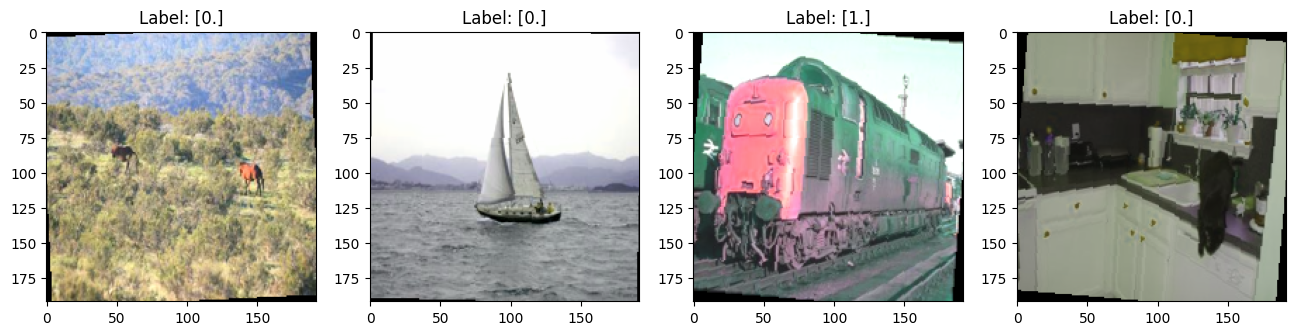

Batch shapes: (32, 192, 192, 3) (32, 1)
Batch xs min, max: 0.0 1.0


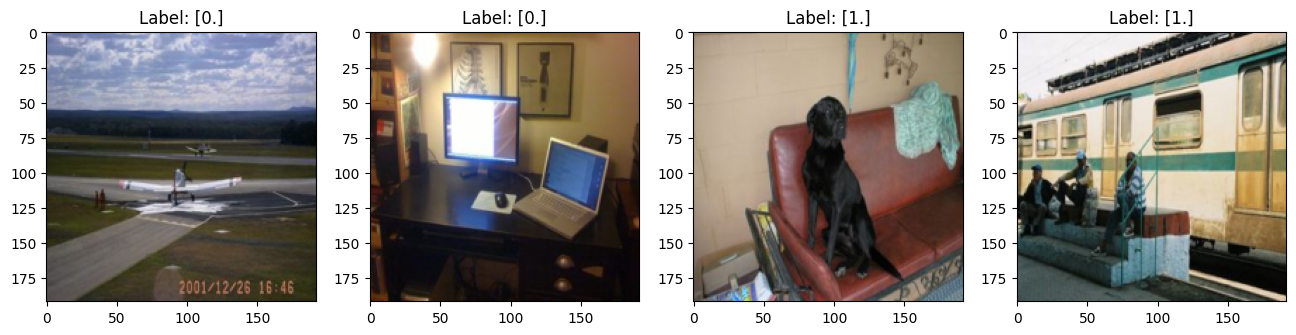

In [51]:
# implement your solution BELOW (No automatic tests for this task)

MOBILENET_MEANS = [0.485, 0.456, 0.406]
MOBILENET_STDS = [0.229, 0.224, 0.225]


for sample_xs, sample_ys in dataloader_train:
  sample_xs = sample_xs.permute(0, 2, 3, 1)
  sample_xs = sample_xs.numpy()
  sample_xs = (sample_xs * MOBILENET_STDS) + MOBILENET_MEANS
  sample_xs = np.clip(sample_xs, 0.0, 1.0)
  sample_ys = sample_ys.numpy()

  break


fig, axes = plt.subplots(1, 4, figsize=(16, 4))
print("Batch shapes:", sample_xs.shape, sample_ys.shape)
print("Batch xs min, max:", np.amin(sample_xs), np.amax(sample_xs))
for i in range(4):
  axes[i].imshow(sample_xs[i,:,:,:])
  axes[i].set_title("Label: " + str(sample_ys[i]))

plt.show()

for sample_xs, sample_ys in dataloader_val:
  sample_xs = sample_xs.permute(0, 2, 3, 1)
  sample_xs = sample_xs.numpy()
  sample_xs = (sample_xs * MOBILENET_STDS) + MOBILENET_MEANS
  sample_xs = np.clip(sample_xs, 0.0, 1.0)
  sample_ys = sample_ys.numpy()
  break

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
print("Batch shapes:", sample_xs.shape, sample_ys.shape)
print("Batch xs min, max:", np.amin(sample_xs), np.amax(sample_xs))
for i in range(4):
  axes[i].imshow(sample_xs[i,:,:,:])
  axes[i].set_title("Label: " + str(sample_ys[i]))

plt.show()






### **F**: A háló betanítása bináris klasszifikációs feladatra - 7 pont

**Tanítsd be a** `finetuned_model` **neuronhálót** a tanítóhalmazon a `dataloader_train` iterátor segítségével és alkalmazd a `dataloader_val` iterátort a validációhoz!

Alkalmazd a bináris klasszifikációkor szokásosan használt költséget! **Mérd le minden epoch-ban a tanító- és a validációs halmazon mért költségeket, majd a tanítás végeztével rajzold ki ezeknek az értékeknek a tanítás során való alakulását egy közös grafikonon!** A grafikonon a jelmagyarázat meglétére és a görbék könnyű elkülöníthetőségére figyelj ezúttal is! **Számold ki a (bináris) _accuracy_ (pontosság) metrikát minden epoch-ban a tanító- és a validációs halmazon** és jelöld ezek alakulását is a grafikonon!

A tanítást az **early stopping** technika állítsa le! Amennyiben adott számú epoch-on keresztül (`patience`) nem javul a validációs költség, érjen véget a betanítás és **állítsuk vissza az `finetuned_model` súlyait abból az epoch-ból, amikor a legjobb volt a validációs költség!** Mindez automatikusan történjen!

A betanítást követően **számold ki a _(bináris) accuracy_ metrikát a teszt-iterátorból mintavételezett példahalmazon** és add értékül a kapott számot a `test_acc` változónak!

_**Megjegyzés:** Megfelelően választott tanulási rátával 1 perc (CPU) tanítás elegendő a tesztelő által elvárt metrikák eléréséhez (akár 2-3 epoch)._

Epoch #0, tr loss: 0.4318016767501831, val loss: 0.2542617917060852, tr acc: 0.8240740895271301, val acc: 0.8928571343421936
    Early stopping: Best model updated.
Epoch #1, tr loss: 0.19596299529075623, val loss: 0.21744418144226074, tr acc: 0.9270833134651184, val acc: 0.9151785969734192
    Early stopping: Best model updated.
Epoch #2, tr loss: 0.15133024752140045, val loss: 0.22672785818576813, tr acc: 0.9375, val acc: 0.9285714030265808
Best model weights are restored.
Test metrics - BCE: 0.2819300591945648, acc: 0.9200000166893005
Test sample #0, pred vs true label: 1 vs [1.]
Test sample #1, pred vs true label: 1 vs [1.]
Test sample #2, pred vs true label: 1 vs [1.]
Test sample #3, pred vs true label: 1 vs [1.]
Test sample #4, pred vs true label: 1 vs [1.]
Test sample #5, pred vs true label: 0 vs [0.]
Test sample #6, pred vs true label: 0 vs [0.]
Test sample #7, pred vs true label: 1 vs [1.]
Test sample #8, pred vs true label: 1 vs [1.]
Test sample #9, pred vs true label: 1 vs [

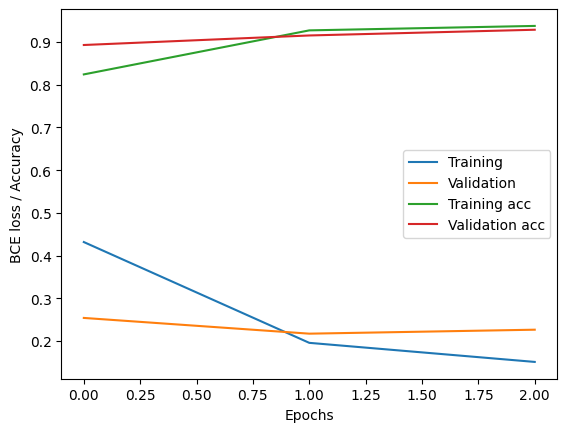

Tester: Task F  - achieved metrics are OK.


In [28]:
# implement your solution BELOW


@torch.no_grad()
def acc_fn(y_hat, y_true):
    y_hat_am = (y_hat >= 0.5).float()
    return torch.count_nonzero(y_hat_am == y_true) / y_hat.shape[0]

loss_fn = nn.BCELoss()

n_epochs = 3
learning_rate = 0.001
optimizer = torch.optim.Adam(finetuned_model.parameters(), lr=learning_rate)

train_losses = []
val_losses = []
train_accuracy = []
val_accuracy = []
best_finetuned_model = None
best_val_loss = float('inf')
early_stopping_patience = 5
last_early_stopping_update_ep_idx = 0

for epoch_idx in range(n_epochs):
  finetuned_model.train()
  train_epoch_losses = []
  train_epoch_accs = []

  for x, y in dataloader_train:

    optimizer.zero_grad()
    y_hat = finetuned_model(x)
    loss = loss_fn(y_hat, y)
    acc = acc_fn(y_hat, y)
    train_epoch_losses.append(loss.detach())
    train_epoch_accs.append(acc)
    loss.backward()
    optimizer.step()


  train_epoch_losses = torch.tensor(train_epoch_losses)
  train_epoch_accs = torch.tensor(train_epoch_accs)
  avg_tr_epoch_loss = train_epoch_losses.mean()
  avg_tr_epoch_acc = train_epoch_accs.mean()
  train_losses.append(avg_tr_epoch_loss)
  train_accuracy.append(avg_tr_epoch_acc)

  finetuned_model.eval()
  val_epoch_losses = []
  val_epoch_accs = []

  for x, y in dataloader_val:

    with torch.no_grad():
      y_hat = finetuned_model(x)

    loss = loss_fn(y_hat, y)
    acc = acc_fn(y_hat, y)
    val_epoch_losses.append(loss)
    val_epoch_accs.append(acc)

  val_epoch_losses = torch.tensor(val_epoch_losses)
  val_epoch_accs = torch.tensor(val_epoch_accs)
  avg_val_epoch_loss = val_epoch_losses.mean()
  avg_val_epoch_acc = val_epoch_accs.mean()
  val_losses.append(avg_val_epoch_loss)
  val_accuracy.append(avg_val_epoch_acc)

  print(f"Epoch #{epoch_idx}, tr loss: {avg_tr_epoch_loss}, val loss: {avg_val_epoch_loss}, tr acc: {avg_tr_epoch_acc}, val acc: {avg_val_epoch_acc}")


  if avg_val_epoch_loss < best_val_loss:
    best_val_loss = avg_val_epoch_loss
    best_finetuned_model = copy.deepcopy(finetuned_model)
    last_early_stopping_update_ep_idx = epoch_idx
    print("    Early stopping: Best model updated.")


  if last_early_stopping_update_ep_idx + early_stopping_patience < epoch_idx:
    print("Training is terminated by early stopping.")
    break


print("Best model weights are restored.")
finetuned_model = best_finetuned_model


test_pred_y_cat = []
test_y_cat = []

with torch.no_grad():
    _, (test_x, test_y) = next(enumerate(dataloader_test))
    test_x = test_x
    test_pred_y_cat_batch_npy = (finetuned_model(test_x) >= 0.5).int().flatten().numpy()
    test_pred_y_cat.append(test_pred_y_cat_batch_npy)
    test_y_cat.append(test_y.numpy())
test_pred_y_cat = np.concatenate(test_pred_y_cat, axis=0)
test_y_cat = np.concatenate(test_y_cat, axis=0)


with torch.no_grad():
  test_pred_ys = []
  test_ys = []
  for x, y in dataloader_test:
    y_hat = finetuned_model(x)
    test_pred_ys.append(y_hat)
    test_ys.append(y)

  test_pred_ys = torch.cat(test_pred_ys, dim=0)
  test_ys = torch.cat(test_ys, dim=0)
  test_bce = loss_fn(test_pred_ys, test_ys)
  test_acc = acc_fn(test_pred_ys, test_ys)
  print(f"Test metrics - BCE: {test_bce}, acc: {test_acc}")

for sample_idx in range(10):
  print(f"Test sample #{sample_idx}, pred vs true label: {test_pred_y_cat[sample_idx]} vs {test_y_cat[sample_idx]}")

plt.plot(train_losses, label='Training')
plt.plot(val_losses, label='Validation')
plt.plot(train_accuracy, label='Training acc')
plt.plot(val_accuracy, label='Validation acc')
plt.xlabel('Epochs')
plt.ylabel('BCE loss / Accuracy')
plt.legend()
plt.show()



# implement your solution ABOVE

tester.test('F', test_acc)

### **G**: Montázs - 4 + 5 pont

_(Ennek a feladatnak a megoldásához nincs szükség a többi feladat megoldására)._

Szeretnél egy szép montázst készíteni az adatbázis képeiből, melyet aztán kinyomtatva, molinóként, különböző rendezvényekre vihetsz el. Feladatod ennek a montázs-képnek az elkészítése.

#### **Alapfeladat**: 4 pont

Válassz egy kategóriát az eredeti adatbázis objektum-kategóriái közül, majd válassz az ezeket a típusú objektumokat tartalmazó képek közül néhányat (a példa ábrához 15 képet választottunk). A notebook elején létrehozott `jpg_ims` és `label_ims` tömbökből tudsz kiindulni. Utóbbin az 1, 2, ..., 20 értékű pixelek reprezentálják a húszféle objektum-kategória jelenlétét.

A montázs-képet az alábbiak szerinted tudod elkészíteni:
- Rendezd sorba a választott képeket aszerint, hogy hány pixelnyi található belőle a kiválasztott kategóriából! Kerüljön előre az a kép, amelyen a legkevesebb pixelnyi található meg a választott kategóriából!
- A montázs minden egyes pixelét adja a sorrendben legelső olyan kép azonos pozícióban található pixele, ahol ez az adott pixel a választott kategóriához tartozik!
- Azokon a pixel pozíciókon, ahol egyik választott képen sincs éppen a kiválasztott kategória, ott legyen a montázs-kép megfeleő pixelének színe egy konstans háttérszín!

**Készítsd el a montázs-képet, majd rajzold ki azt a sorba rendezett, választott képekkel együtt! Bármilyen olyan megoldásért jár az alapfeladat teljes pontszáma, ahol a fent leírtak szerint készített montázzsal logikailag ekvivalens kép keletkezik.**

#### **Extra feladat**: további 5 pont

Próbálj, ahol csak lehet, hatékony, vektorizált megoldást adni. A megoldásod hatékonyságától függően kaphatsz pontokat. Teljesen vektorizált megoldás esetén jár a teljes pontszám: ehhez semmilyen ciklust, vagy annak megfelelő hatékonyságú szerkezetet nem használhatsz! Ez alól kivétel a képek kirajzolásához szükséges kód, pl. Matplotlib subplot-okon való iteráláshoz természetesen használhatsz ciklust.

<br>
<img src="./zh_files/taskG_figure.jpg" style="display:inline-block" width='80%'>


In [63]:
# Note that a pairwise comparison of all pixels in all images against an array with 20 elements at the same time can use up all the available memory.

SELECTED_CAT_IDX = 17                            # you can choose another one if you want
BACKGROUND_COLOR_RGB = [150, 180, 100]           # you can choose another one if you want

# implement your solution BELOW (No automatic tests for this task)


n_images = label_ims.shape[0]
#labels = np.full((n_images,), dtype=np.uint8, fill_value=99)
cat_imgs = np.zeros_like(jpg_ims)
cat_labels = np.zeros_like(label_ims)
for i in range(n_images):
    if np.any(label_ims[i] == 17):
        cat_imgs[i] = jpg_ims[i]
        cat_labels[i] = label_ims

#cat_labels = cat_labels[:15]
num_of_pixels_list = np.zeros(15)
for im_idx in range(15):
    c_categories = np.bincount(cat_labels[im_idx, :, :].reshape(-1), minlength=21)
    num_of_pixels_list[im_idx] = c_categories[17]

print(num_of_pixels_list)
ims_sorter = np.argwhere(num_of_pixels_list)
sorted_ims = cat_ims[ims_sorter]


fig, axes = plt.subplots(3, 5, figsize=(16, 4))
for i in range(3):
    for j in range(5):
      axes[i][j].imshow(sorted_ims[0])
    print("Batch shapes:", sample_xs.shape)
    print("Batch xs min, max:", np.amin(sample_xs), np.amax(sample_xs))
    
plt.show()




ValueError: could not broadcast input array from shape (2913,240,320) into shape (240,320)